<a href="https://colab.research.google.com/github/Research-methods-group5/Hackathon_groupO/blob/main/Dataset_C_Data_Science_Challenge(24077147).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset C
#Dharanidhar Beere
**Data Science Challenge**

This notebook performs EDA, preprocessing, model comparison, cross-validation, hyperparameter tuning, explainability and ranked predictions.

**Target:** `covid_vaccine` (0 = No, 1 = Yes)

## 1. Imports and load the data

In [20]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from scipy.stats import randint, uniform
import joblib

# If running in Colab, uncomment:
# from google.colab import files
# uploaded = files.upload()

train = pd.read_csv("dataset_C_training.csv")
test = pd.read_csv("dataset_C_testing.csv")

print("Training shape:", train.shape)
print("Testing shape:", test.shape)
display(train.head())

Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


## 2. Data quality checks

In [21]:
TARGET = "covid_vaccine"
ID_COL = "respondent_id"

print("Training duplicates:", train.duplicated().sum())
print("Testing duplicates:", test.duplicated().sum())
print("Duplicate training IDs:", train[ID_COL].duplicated().sum())
print("Duplicate testing IDs:", test[ID_COL].duplicated().sum())
print("Train/test ID overlap:", len(set(train[ID_COL]) & set(test[ID_COL])))

quality = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": (train.isna().mean() * 100).round(2),
    "data_type": train.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)
display(quality)

print("\nTarget counts:")
display(train[TARGET].value_counts().rename_axis("class").to_frame("records"))
display((train[TARGET].value_counts(normalize=True) * 100).round(2).rename("percent"))

Training duplicates: 0
Testing duplicates: 0
Duplicate training IDs: 0
Duplicate testing IDs: 0
Train/test ID overlap: 0


,missing_count,missing_percent,data_type
employment_sector,2330,48.99,object
health_insurance,1908,40.12,float64
income_poverty,748,15.73,object
rent_or_own,329,6.92,object
employment_status,238,5.00,object
marital_status,231,4.86,object
education,228,4.79,object
child_under_6_months,135,2.84,float64
health_worker,132,2.78,float64
opinion_covid_sick_from_vacc,90,1.89,float64



Target counts:


,records
class,
0,3202
1,1554


,percent
covid_vaccine,
0,67.33
1,32.67


## 3. Exploratory Data Analysis

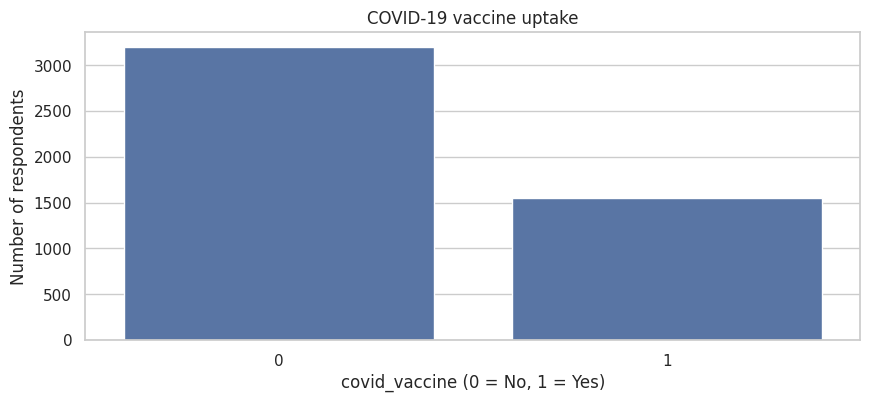

In [22]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10,4))
sns.countplot(data=train, x=TARGET)
plt.title("COVID-19 vaccine uptake")
plt.xlabel("covid_vaccine (0 = No, 1 = Yes)")
plt.ylabel("Number of respondents")
plt.show()

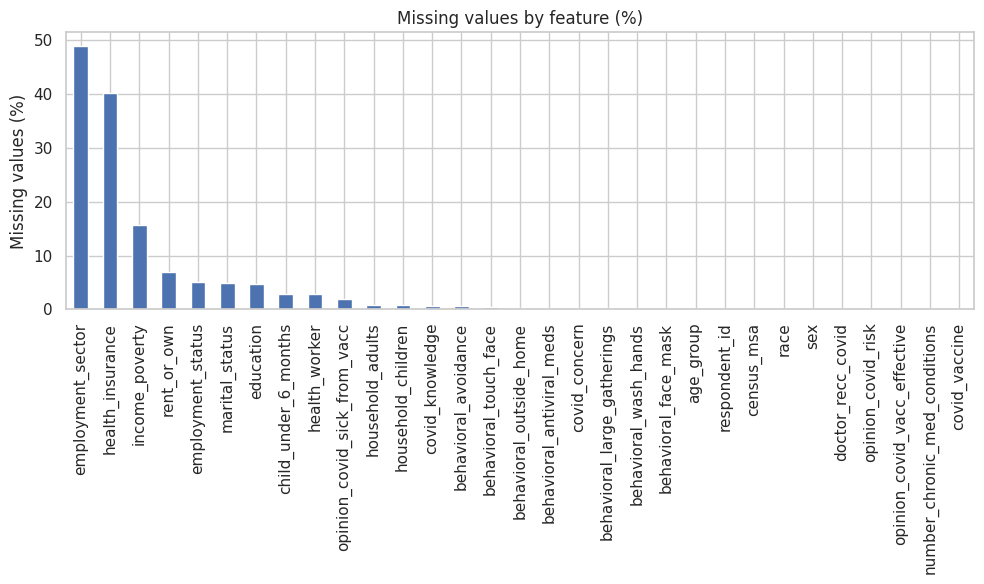

In [23]:

plt.figure(figsize=(10,6))
(train.isna().mean().mul(100).sort_values(ascending=False)
 .plot(kind="bar"))
plt.title("Missing values by feature (%)")
plt.ylabel("Missing values (%)")
plt.tight_layout()
plt.show()

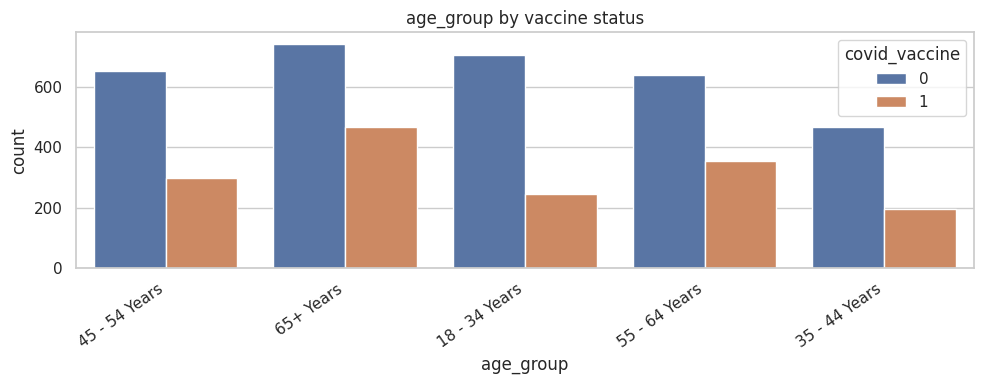

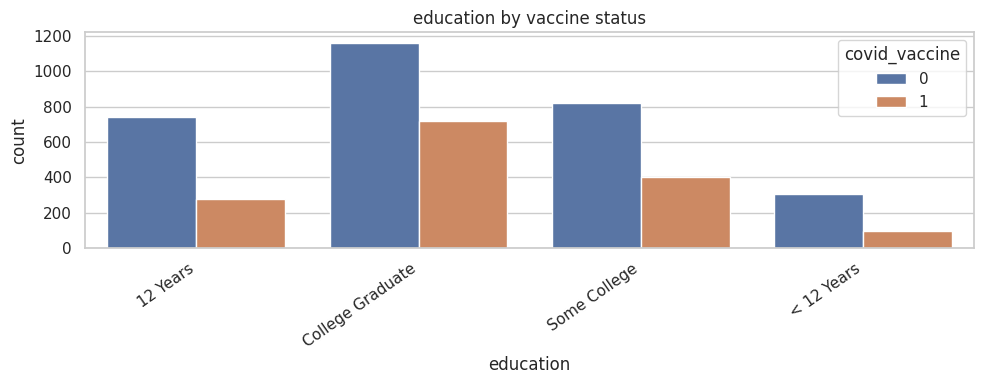

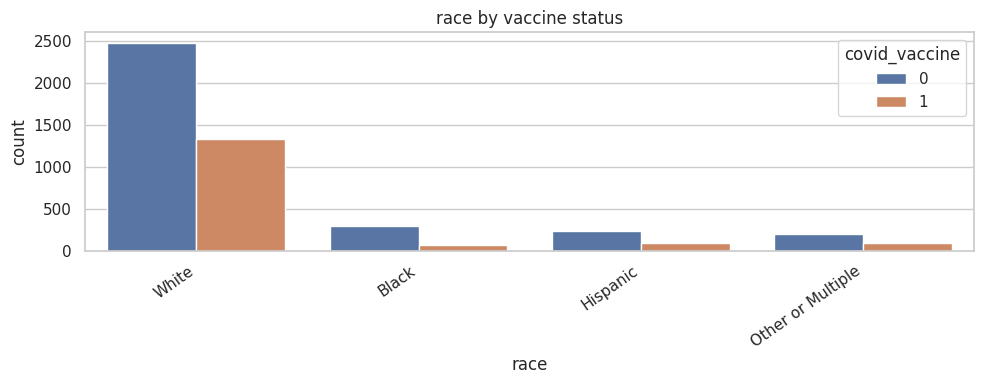

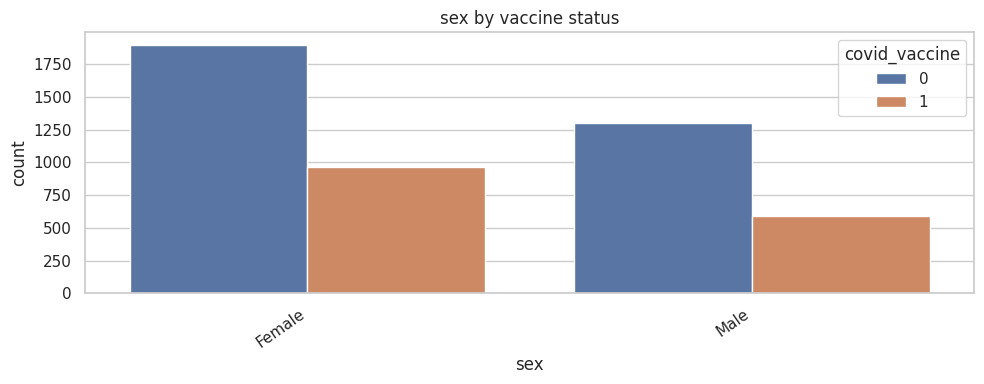

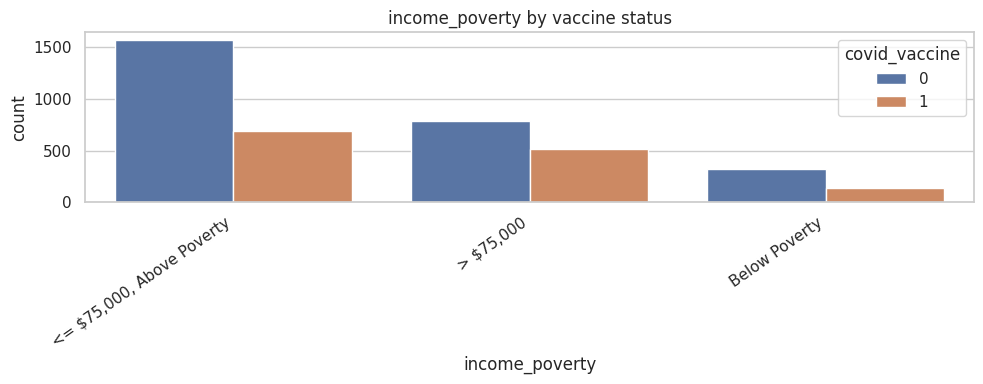

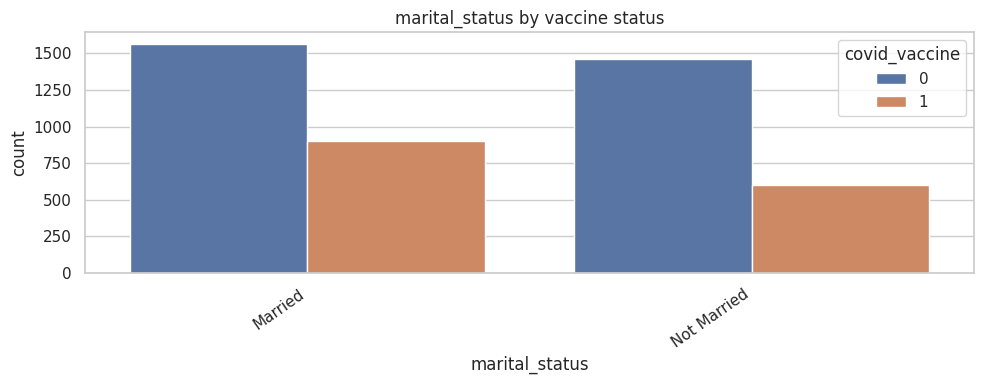

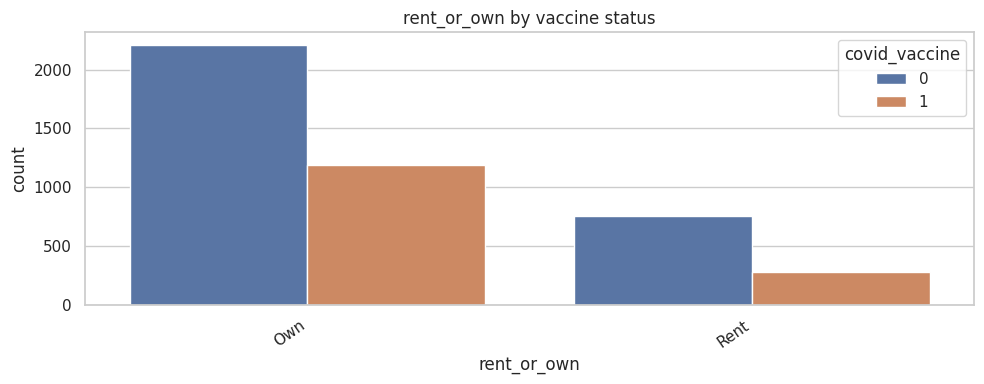

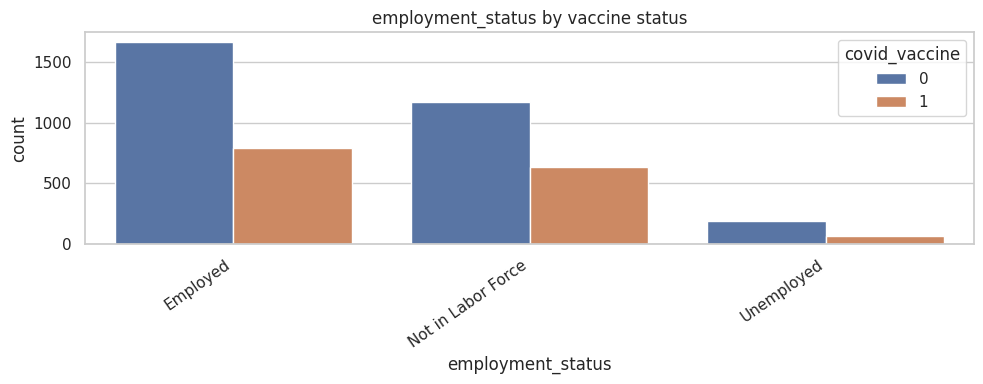

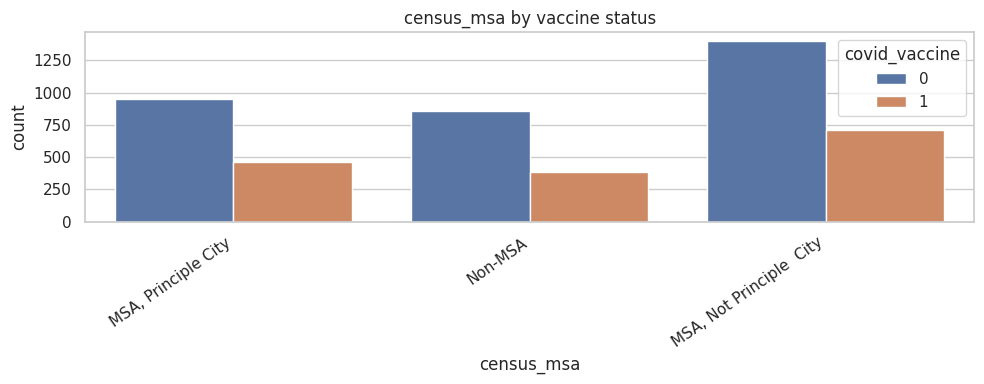

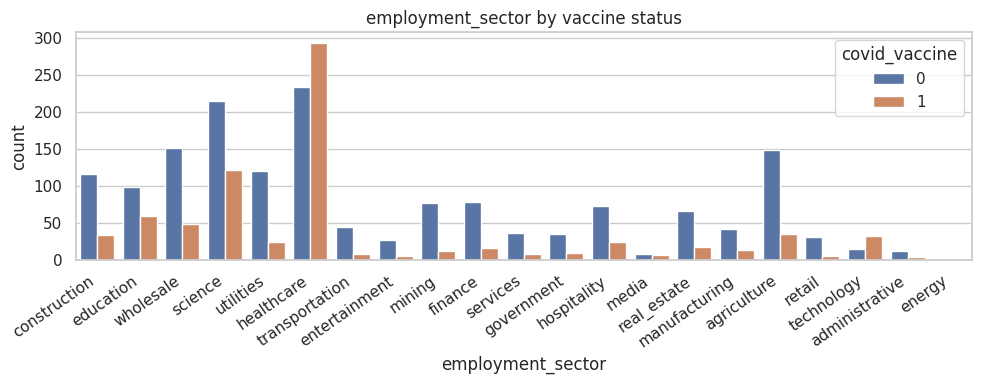

In [24]:
# Categorical feature distributions against the target
categorical_cols = train.select_dtypes(include=["object"]).columns.tolist()
for col in categorical_cols:
    plt.figure(figsize=(10,4))
    sns.countplot(data=train, x=col, hue=TARGET)
    plt.title(f"{col} by vaccine status")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

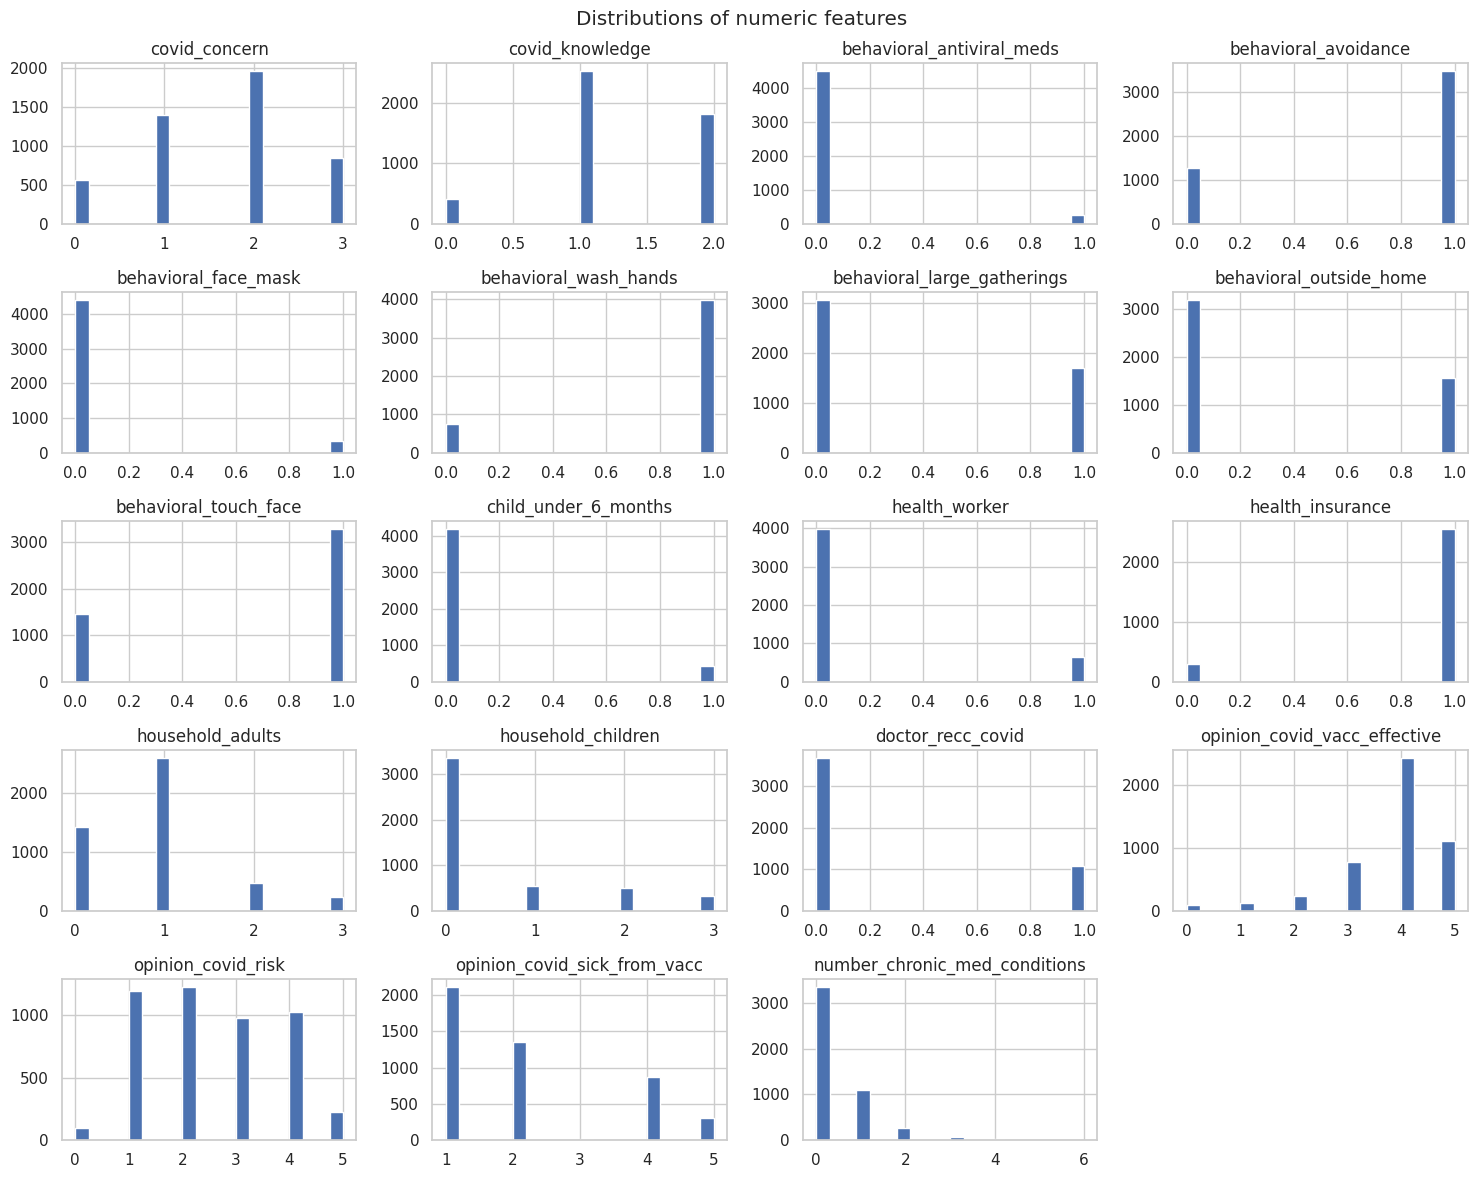

In [25]:
# Numeric feature distributions
numeric_cols = train.select_dtypes(include=np.number).columns.drop([ID_COL, TARGET], errors="ignore")
train[numeric_cols].hist(figsize=(15,12), bins=20)
plt.suptitle("Distributions of numeric features")
plt.tight_layout()
plt.show()

## 4. Prepare features and validation split

In [26]:
# respondent_id is an identifier, not a meaningful predictor.
X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].astype(int)
X_test = test.drop(columns=[ID_COL])

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

# Numeric missing values: median; categorical missing values: most frequent.
# One-hot encoding handles nominal categories without imposing a false order.
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Train split:", X_train.shape, "Validation split:", X_valid.shape)

Train split: (3804, 29) Validation split: (952, 29)


## 5. Compare baseline models

In [27]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=2,
        eval_metric="logloss", random_state=42, n_jobs=-1
    )
}

fitted_models = {}
rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    probabilities = pipe.predict_proba(X_valid)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    fitted_models[name] = pipe
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_valid, predictions),
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1": f1_score(y_valid, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, probabilities),
        "PR-AUC": average_precision_score(y_valid, probabilities)
    })

comparison = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False)
display(comparison.round(3))

,Model,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
3,XGBoost,0.806,0.753,0.754,0.601,0.669,0.832,0.718
0,Logistic Regression,0.770,0.763,0.624,0.743,0.678,0.828,0.719
1,Random Forest,0.795,0.750,0.715,0.621,0.664,0.826,0.701
2,Extra Trees,0.784,0.743,0.684,0.627,0.654,0.823,0.698


## 6. Cross-validation

In [28]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_rows = []

for name, estimator in models.items():

    # Keep preprocessing inside the pipeline to prevent data leakage
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipe,
        X_train,                 # Training data only
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "f1": "f1",
            "precision": "precision",
            "recall": "recall"
        },
        n_jobs=-1,
        error_score="raise"
    )

    cv_rows.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean()
    })

cv_results = pd.DataFrame(cv_rows)

cv_results = cv_results.sort_values(
    "Mean ROC-AUC",
    ascending=False
)

display(cv_results.round(4))


,Model,Mean ROC-AUC,ROC-AUC Std,Mean F1,Mean Precision,Mean Recall
3,XGBoost,0.8397,0.0168,0.6530,0.7365,0.5873
1,Random Forest,0.8294,0.0152,0.6511,0.7020,0.6082
0,Logistic Regression,0.8266,0.0133,0.6738,0.6251,0.7313
2,Extra Trees,0.8209,0.0147,0.6577,0.7096,0.6138


## 7. Hyperparameter tuning (XGBoost)

In [29]:
xgb_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        random_state=42, n_jobs=-1, tree_method="hist"
    ))
])

parameter_space = {
    "model__n_estimators": randint(200, 650),
    "model__max_depth": randint(2, 6),
    "model__learning_rate": uniform(0.02, 0.08),
    "model__subsample": uniform(0.70, 0.30),
    "model__colsample_bytree": uniform(0.70, 0.30),
    "model__min_child_weight": randint(1, 8),
    "model__reg_lambda": uniform(1, 5)
}

search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=parameter_space,
    n_iter=10,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)
search.fit(X_train, y_train)
print("Best cross-validation ROC-AUC:", search.best_score_)
print("Best parameters:", search.best_params_)
best_model = search.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best cross-validation ROC-AUC: 0.8395383902071135
Best parameters: {'model__colsample_bytree': np.float64(0.7139351238159992), 'model__learning_rate': np.float64(0.06860358815211508), 'model__max_depth': 2, 'model__min_child_weight': 1, 'model__n_estimators': 366, 'model__reg_lambda': np.float64(1.0663248057993326), 'model__subsample': np.float64(0.9826605267054558)}


## 8. Evaluate tuned model on the untouched validation split

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       641
           1       0.74      0.58      0.65       311

    accuracy                           0.80       952
   macro avg       0.78      0.74      0.75       952
weighted avg       0.79      0.80      0.79       952

Accuracy: 0.7962
Balanced accuracy: 0.7411
ROC-AUC: 0.8353
PR-AUC: 0.7194


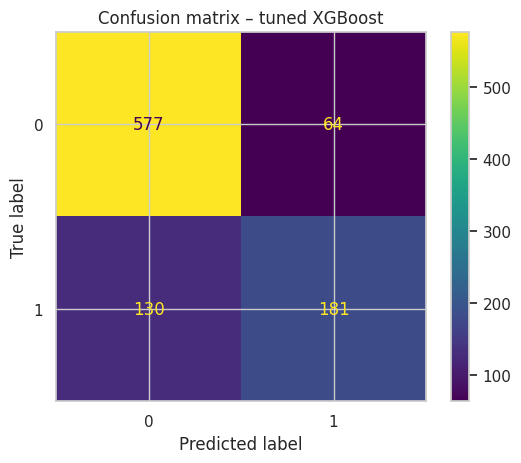

In [30]:
valid_prob = best_model.predict_proba(X_valid)[:, 1]
valid_pred = (valid_prob >= 0.5).astype(int)

print(classification_report(y_valid, valid_pred, zero_division=0))
print("Accuracy:", round(accuracy_score(y_valid, valid_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_valid, valid_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, valid_prob), 4))
print("PR-AUC:", round(average_precision_score(y_valid, valid_prob), 4))

ConfusionMatrixDisplay.from_predictions(y_valid, valid_pred)
plt.title("Confusion matrix – tuned XGBoost")
plt.show()

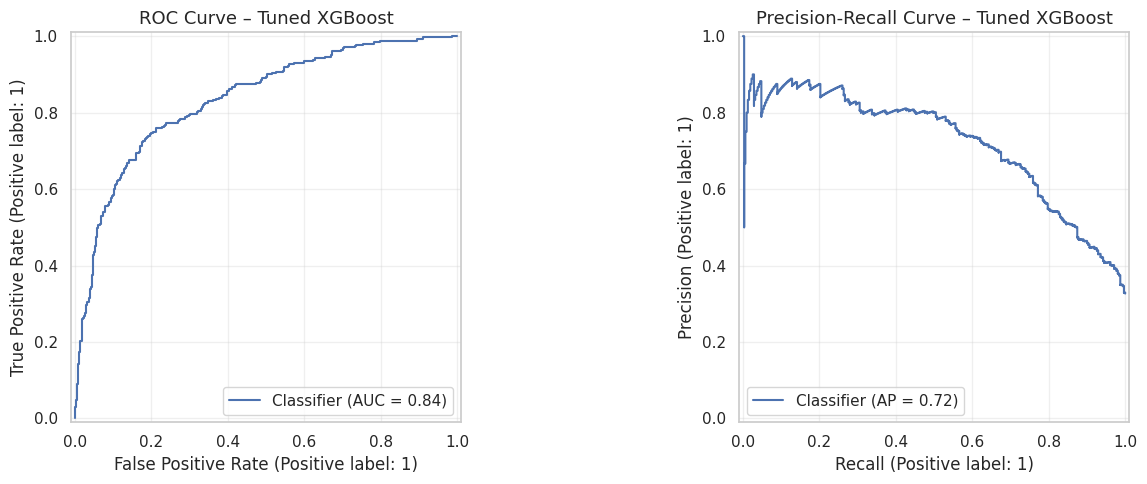

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
RocCurveDisplay.from_predictions(
    y_valid, valid_prob, ax=axes[0]
)
axes[0].set_title("ROC Curve – Tuned XGBoost", fontsize=13)
axes[0].grid(alpha=0.3)

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_valid, valid_prob, ax=axes[1]
)
axes[1].set_title("Precision-Recall Curve – Tuned XGBoost", fontsize=13)
axes[1].grid(alpha=0.3)

# Display both plots
plt.tight_layout()
plt.show()


## 9. Threshold analysis

In [32]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_valid, pred)
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

# Choose threshold based on the assignment's stated objective and error costs.
# Do not assume the listed vaccine/hospitalisation amounts directly define FP/FN costs.

,Threshold,Accuracy,Precision,Recall,F1,Balanced accuracy
0,0.20,0.685,0.511,0.846,0.637,0.726
1,0.25,0.730,0.561,0.797,0.659,0.747
2,0.30,0.769,0.619,0.759,0.682,0.766
3,0.35,0.788,0.658,0.730,0.692,0.773
4,0.40,0.793,0.686,0.675,0.681,0.763
5,0.45,0.798,0.716,0.633,0.672,0.756
6,0.50,0.796,0.739,0.582,0.651,0.741
7,0.55,0.797,0.768,0.543,0.637,0.732
8,0.60,0.796,0.797,0.505,0.618,0.721
9,0.65,0.785,0.805,0.450,0.577,0.699


## 10. Explainability – SHAP

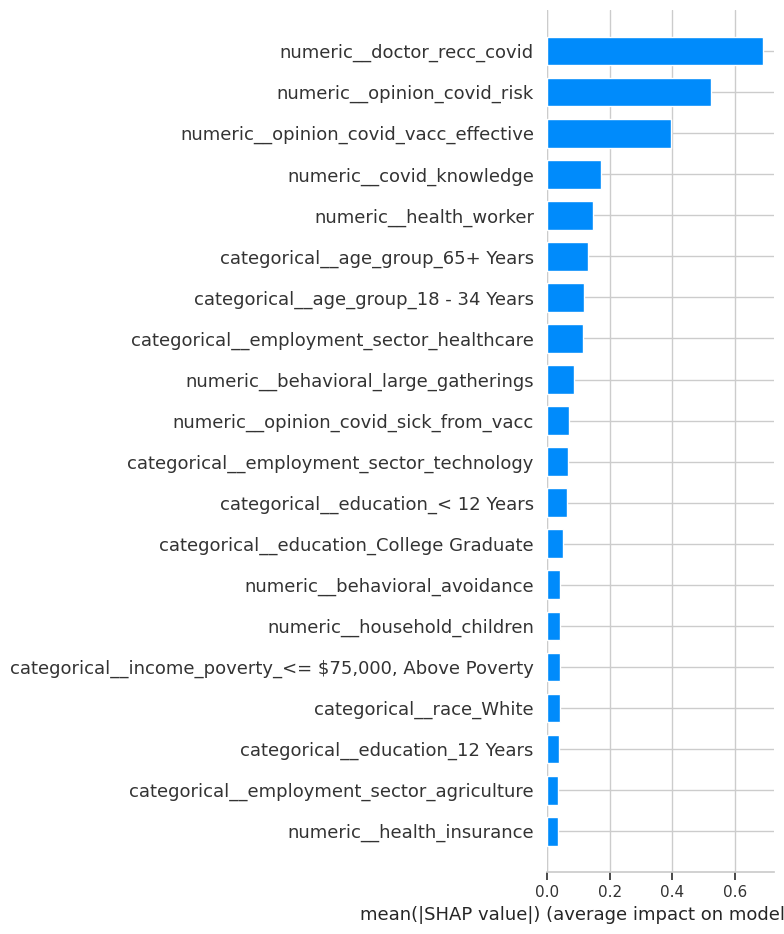

In [33]:
# Install if needed: %pip install shap
import shap

fitted_preprocessor = best_model.named_steps["preprocess"]
fitted_xgb = best_model.named_steps["model"]

X_valid_transformed = fitted_preprocessor.transform(X_valid)
feature_names = fitted_preprocessor.get_feature_names_out()

# Use a manageable sample for SHAP explanations.
sample_size = min(300, X_valid_transformed.shape[0])
explainer = shap.TreeExplainer(fitted_xgb)
shap_values = explainer.shap_values(X_valid_transformed[:sample_size])

shap.summary_plot(
    shap_values,
    X_valid_transformed[:sample_size],
    feature_names=feature_names,
    plot_type="bar",
    show=True
)


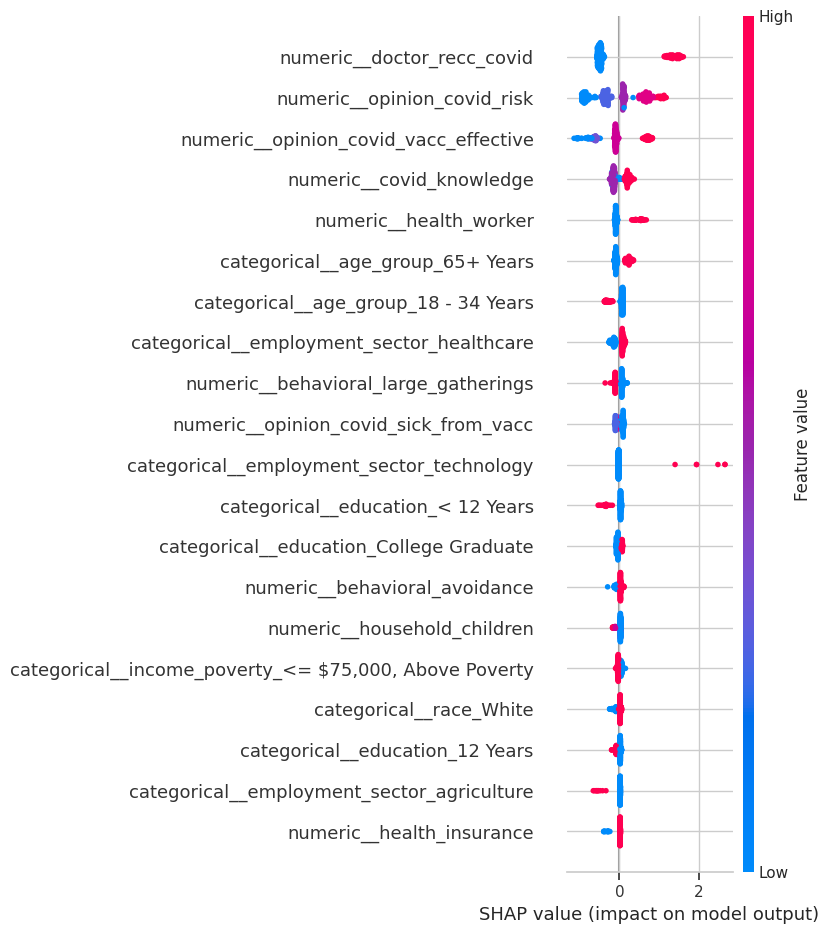

In [34]:
shap.summary_plot(
    shap_values,
    X_valid_transformed[:sample_size],
    feature_names=feature_names,
    show=True
)

,Feature,Importance Mean,Importance Std
23,doctor_recc_covid,0.0933,0.0073
25,opinion_covid_risk,0.0556,0.0092
24,opinion_covid_vacc_effective,0.0281,0.0053
27,employment_sector,0.0099,0.0032
10,health_worker,0.0090,0.0029
12,age_group,0.0050,0.0031
13,education,0.0044,0.0023
14,race,0.0032,0.0009
6,behavioral_large_gatherings,0.0009,0.0014
4,behavioral_face_mask,0.0006,0.0005


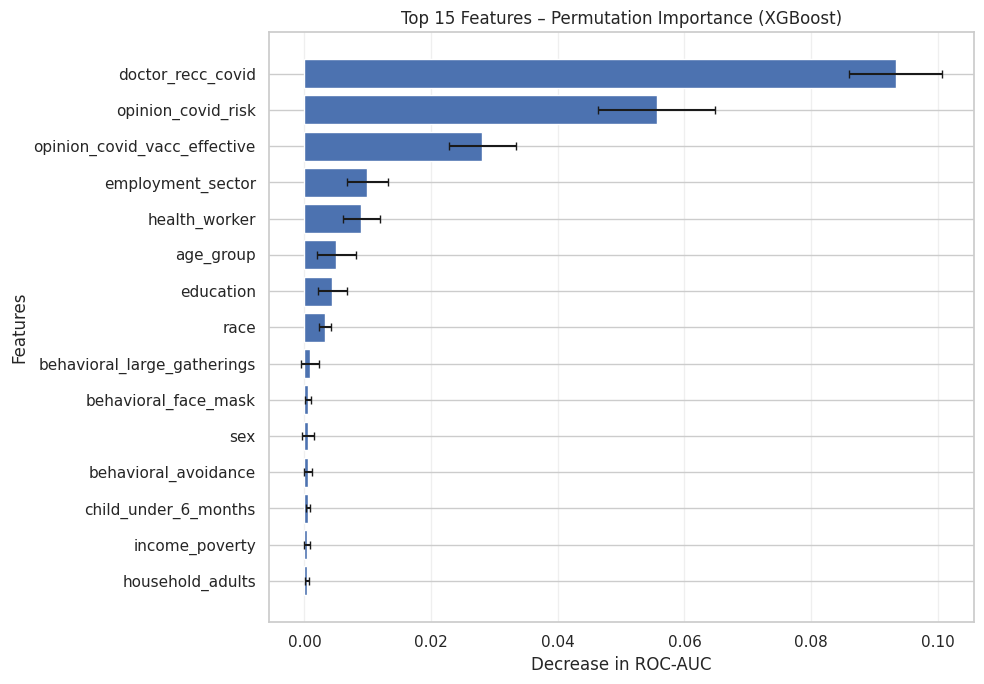

In [35]:

# 11. Explainability – Permutation Feature Importance

from sklearn.inspection import permutation_importance

# Use the tuned XGBoost pipeline and validation dataset
perm_results = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a feature importance dataframe
permutation_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance Mean": perm_results.importances_mean,
    "Importance Std": perm_results.importances_std
})

# Sort features by importance
permutation_df = permutation_df.sort_values(
    by="Importance Mean",
    ascending=False
)

# Display the top 15 features
display(permutation_df.head(15).round(4))

# Visualise the top 15 features
top_features = permutation_df.head(15).sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"],
    capsize=3
)

plt.xlabel("Decrease in ROC-AUC")
plt.ylabel("Features")
plt.title("Top 15 Features – Permutation Importance (XGBoost)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Fit final model and generate ranked test predictions

In [38]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

# Unit costs ($)
COST_TP = 1500.0   # Vaccine administration ($1,500)
COST_FP = 1500.0   # Wasted outreach ($1,500)
COST_FN = 41000.0  # Hospitalisation penalty for missed unvaccinated individual ($41,000)
COST_TN = 0.0      # Zero cost ($0)

candidate_models = {
    "XGBoost_Tuned": best_model,
    "XGBoost_Baseline": fitted_models["XGBoost"],
    "Random_Forest": fitted_models["Random Forest"],
    "Logistic_Regression": fitted_models["Logistic Regression"],
    "Extra_Trees": fitted_models["Extra Trees"]
}

def evaluate_model_cost(y_true, y_prob):
    """Finds the best decision threshold for a specific model's probabilities."""
    best_cost = float("inf")
    best_thresh = 0.50
    best_metrics = {}

    for thresh in np.arange(0.05, 0.81, 0.05):
        pred = (y_prob >= thresh).astype(int)

        tp = np.sum((y_true == 1) & (pred == 1))
        fp = np.sum((y_true == 0) & (pred == 1))
        fn = np.sum((y_true == 1) & (pred == 0))
        tn = np.sum((y_true == 0) & (pred == 0))

        total_cost = (tp * COST_TP) + (fp * COST_FP) + (fn * COST_FN) + (tn * COST_TN)
        cost_per_pred = total_cost / len(y_true)

        if cost_per_pred < best_cost:
            best_cost = cost_per_pred
            best_thresh = thresh
            best_metrics = {
                "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                "total_cost": total_cost,
                "cost_per_pred": cost_per_pred
            }

    return best_thresh, best_metrics

model_scores = []

for name, model in candidate_models.items():
    val_prob = model.predict_proba(X_valid)[:, 1]
    roc_auc = roc_auc_score(y_valid, val_prob)

    # Optimize threshold specifically for THIS model
    opt_thresh, metrics = evaluate_model_cost(y_valid, val_prob)

    model_scores.append({
        "Model": name,
        "Validation_ROC_AUC": round(roc_auc, 4),
        "Optimal_Threshold": round(opt_thresh, 2),
        "Val_Total_Cost ($)": round(metrics["total_cost"], 2),
        "Val_Cost_Per_Prediction ($)": round(metrics["cost_per_pred"], 2)
    })

# Rank models by minimum total cost
ranking_df = pd.DataFrame(model_scores).sort_values(
    "Val_Cost_Per_Prediction ($)",
    ascending=True
).reset_index(drop=True)

print(" Final Model Ranking (Each Model Self-Optimized):")
display(ranking_df)

best_model_name = ranking_df.loc[0, "Model"]
best_unit_cost = ranking_df.loc[0, "Val_Cost_Per_Prediction ($)"]
best_val_cost = ranking_df.loc[0, "Val_Total_Cost ($)"]
est_test_total_cost = best_unit_cost * len(X_test)

print(f"\n=======================================================")
print(f" BEST PERFORMING MODEL: {best_model_name}")
print(f"  - Optimal Decision Threshold: {ranking_df.loc[0, 'Optimal_Threshold']}")
print(f"  - Cost Per Prediction: ${best_unit_cost:,.2f}")
print(f"  - Total Validation Cost ({len(y_valid)} samples): ${best_val_cost:,.2f}")
print(f"  - Estimated Total Test Cost ({len(X_test)} samples): ${est_test_total_cost:,.2f}")
print(f"=======================================================\n")

# Fit final models and generate predictions
for rank, row in ranking_df.iterrows():
    model_name = row["Model"]
    model_thresh = row["Optimal_Threshold"]

    final_model = clone(candidate_models[model_name])
    final_model.fit(X, y)

    test_prob = final_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= model_thresh).astype(int)

    submission = pd.DataFrame({
        ID_COL: test[ID_COL],
        # "probability_vaccinated": test_prob,
        TARGET: test_pred
    })

    filename = f"submission_{rank + 1}_{model_name}.csv"
    submission.to_csv(filename, index=False)

    est_cost = row['Val_Cost_Per_Prediction ($)'] * len(X_test)
    print(
        f"Saved: {filename:<32} | "
        f"ROC-AUC: {row['Validation_ROC_AUC']:.4f} | "
        f"Thresh: {model_thresh:.2f} | "
        f"Cost/Pred: ${row['Val_Cost_Per_Prediction ($)']:,.2f} | "
        f"Est. Test Total Cost: ${est_cost:,.2f}"
    )

print("\nAll five prediction files generated successfully.")

 Final Model Ranking (Each Model Self-Optimized):


,Model,Validation_ROC_AUC,Optimal_Threshold,Val_Total_Cost ($),Val_Cost_Per_Prediction ($)
0,Random_Forest,0.8259,0.10,1377500.0,1446.95
1,Extra_Trees,0.8226,0.05,1417500.0,1488.97
2,XGBoost_Baseline,0.8322,0.05,1440500.0,1513.13
3,XGBoost_Tuned,0.8353,0.05,1469000.0,1543.07
4,Logistic_Regression,0.8282,0.15,1540500.0,1618.17



 BEST PERFORMING MODEL: Random_Forest
  - Optimal Decision Threshold: 0.1
  - Cost Per Prediction: $1,446.95
  - Total Validation Cost (952 samples): $1,377,500.00
  - Estimated Total Test Cost (4749 samples): $6,871,565.55

Saved: submission_1_Random_Forest.csv   | ROC-AUC: 0.8259 | Thresh: 0.10 | Cost/Pred: $1,446.95 | Est. Test Total Cost: $6,871,565.55
Saved: submission_2_Extra_Trees.csv     | ROC-AUC: 0.8226 | Thresh: 0.05 | Cost/Pred: $1,488.97 | Est. Test Total Cost: $7,071,118.53
Saved: submission_3_XGBoost_Baseline.csv | ROC-AUC: 0.8322 | Thresh: 0.05 | Cost/Pred: $1,513.13 | Est. Test Total Cost: $7,185,854.37
Saved: submission_4_XGBoost_Tuned.csv   | ROC-AUC: 0.8353 | Thresh: 0.05 | Cost/Pred: $1,543.07 | Est. Test Total Cost: $7,328,039.43
Saved: submission_5_Logistic_Regression.csv | ROC-AUC: 0.8282 | Thresh: 0.15 | Cost/Pred: $1,618.17 | Est. Test Total Cost: $7,684,689.33

All five prediction files generated successfully.
